In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:

df_1=pd.read_csv(r'C:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\data\labeled_data.csv')
df_2=pd.read_csv(r'C:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\data\train_E6oV3lV.csv')

In [3]:
df_1.head()

,Unnamed: 0,count,hate_speech,offensive_language,neither,class,tweet
0,0,3,0,0,3,2,!!! RT @mayasolovely: As a woman you shouldn't...
1,1,3,0,3,0,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,2,3,0,3,0,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,3,3,0,2,1,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,4,6,0,6,0,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...


In [4]:
df_2.head()

,id,label,tweet
0,1,0,@user when a father is dysfunctional and is s...
1,2,0,@user @user thanks for #lyft credit i can't us...
2,3,0,bihday your majesty
3,4,0,#model i love u take with u all the time in ...
4,5,0,factsguide: society now #motivation


In [5]:
df_1.info()

<class 'pandas.DataFrame'>
RangeIndex: 24783 entries, 0 to 24782
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Unnamed: 0          24783 non-null  int64
 1   count               24783 non-null  int64
 2   hate_speech         24783 non-null  int64
 3   offensive_language  24783 non-null  int64
 4   neither             24783 non-null  int64
 5   class               24783 non-null  int64
 6   tweet               24783 non-null  str  
dtypes: int64(6), str(1)
memory usage: 1.3 MB


In [6]:
df_2.info()

<class 'pandas.DataFrame'>
RangeIndex: 31962 entries, 0 to 31961
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      31962 non-null  int64
 1   label   31962 non-null  int64
 2   tweet   31962 non-null  str  
dtypes: int64(2), str(1)
memory usage: 749.2 KB


In [7]:
df_1.describe()

,Unnamed: 0,count,hate_speech,offensive_language,neither,class
count,24783.000000,24783.000000,24783.000000,24783.000000,24783.000000,24783.000000
mean,12681.192027,3.243473,0.280515,2.413711,0.549247,1.110277
std,7299.553863,0.883060,0.631851,1.399459,1.113299,0.462089
min,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000
25%,6372.500000,3.000000,0.000000,2.000000,0.000000,1.000000
50%,12703.000000,3.000000,0.000000,3.000000,0.000000,1.000000
75%,18995.500000,3.000000,0.000000,3.000000,0.000000,1.000000
max,25296.000000,9.000000,7.000000,9.000000,9.000000,2.000000


In [8]:
df_2.describe()

,id,label
count,31962.000000,31962.000000
mean,15981.500000,0.070146
std,9226.778988,0.255397
min,1.000000,0.000000
25%,7991.250000,0.000000
50%,15981.500000,0.000000
75%,23971.750000,0.000000
max,31962.000000,1.000000


In [9]:
df_1.isnull().sum()

Unnamed: 0            0
count                 0
hate_speech           0
offensive_language    0
neither               0
class                 0
tweet                 0
dtype: int64

In [10]:
df_2.isnull().sum()

id       0
label    0
tweet    0
dtype: int64

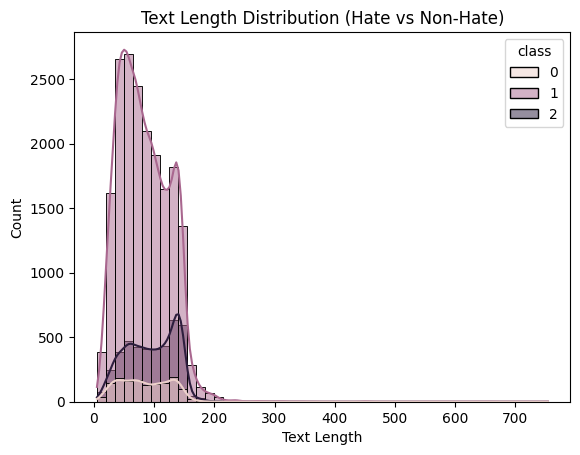

In [12]:
#text length distribution
df_1['text_length'] = df_1['tweet'].apply(len)

sns.histplot(data=df_1, x='text_length', hue='class', bins=50, kde=True)

plt.title("Text Length Distribution (Hate vs Non-Hate)")
plt.xlabel("Text Length")
plt.ylabel("Count")
plt.show()

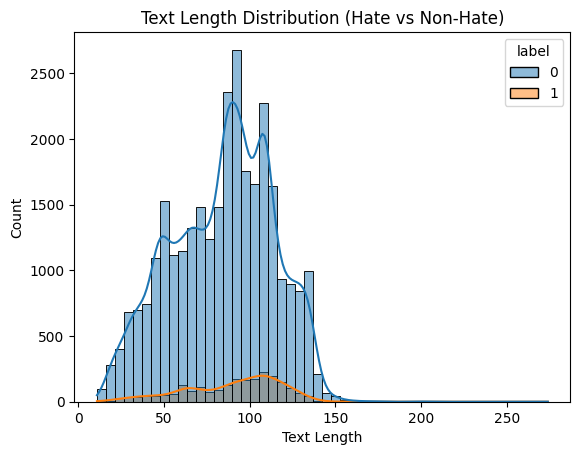

In [14]:
#text length distribution
df_2['text_length'] = df_2['tweet'].apply(len)

sns.histplot(data=df_2, x='text_length', hue='label', bins=50, kde=True)

plt.title("Text Length Distribution (Hate vs Non-Hate)")
plt.xlabel("Text Length")
plt.ylabel("Count")
plt.show()

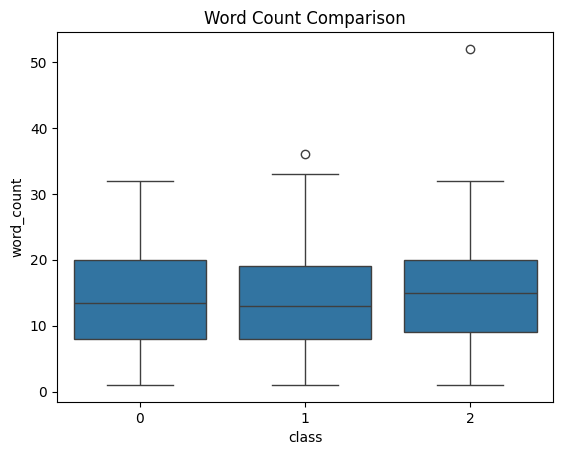

In [15]:
#word count comparison
df_1['word_count'] = df_1['tweet'].apply(lambda x: len(x.split()))

sns.boxplot(x='class', y='word_count', data=df_1)
plt.title("Word Count Comparison")
plt.show()

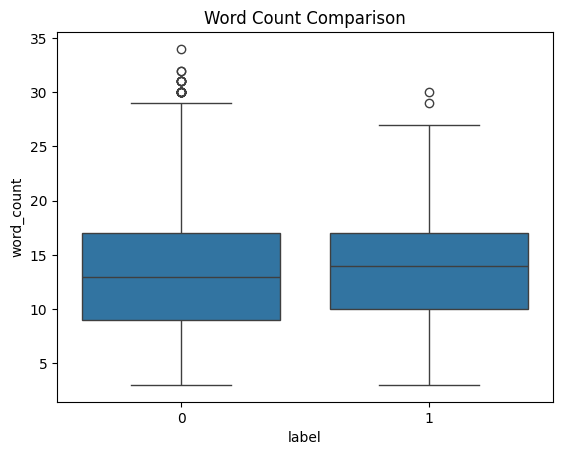

In [16]:
#word count comparison
df_2['word_count'] = df_2['tweet'].apply(lambda x: len(x.split()))

sns.boxplot(x='label', y='word_count', data=df_2)
plt.title("Word Count Comparison")
plt.show()

In [17]:
#most frequent words
from collections import Counter

hate_text = " ".join(df_1[df_1['class']==1]['tweet'])
not_hate_text = " ".join(df_1[df_1['class']==0]['tweet'])

hate_words = Counter(hate_text.split()).most_common(20)
not_hate_words = Counter(not_hate_text.split()).most_common(20)

print("Top Hate Words:", hate_words)
print("Top Non-Hate Words:", not_hate_words)

Top Hate Words: [('a', 7301), ('bitch', 6464), ('RT', 5912), ('I', 5252), ('the', 4545), ('you', 4092), ('to', 3926), ('and', 2639), ('my', 2599), ('that', 2588), ('bitches', 2525), ('like', 2095), ('in', 2061), ('is', 1931), ('me', 1903), ('be', 1872), ('hoes', 1871), ('on', 1869), ('of', 1684), ('pussy', 1667)]
Top Non-Hate Words: [('a', 530), ('the', 349), ('you', 348), ('to', 320), ('RT', 320), ('I', 296), ('and', 219), ('is', 194), ('bitch', 164), ('that', 161), ('like', 157), ('in', 154), ('of', 148), ('faggot', 148), ('be', 129), ('my', 128), ('ass', 127), ('your', 117), ('white', 116), ('are', 112)]


In [18]:
#most frequent words
from collections import Counter

hate_text = " ".join(df_2[df_2['label']==1]['tweet'])
not_hate_text = " ".join(df_2[df_2['label']==0]['tweet'])

hate_words = Counter(hate_text.split()).most_common(20)
not_hate_words = Counter(not_hate_text.split()).most_common(20)

print("Top Hate Words:", hate_words)
print("Top Non-Hate Words:", not_hate_words)

Top Hate Words: [('@user', 1826), ('the', 816), ('a', 607), ('to', 561), ('of', 457), ('is', 425), ('in', 423), ('you', 394), ('and', 358), ('are', 314), ('&amp;', 267), ('for', 239), ('on', 209), ('be', 201), ('i', 200), ('this', 168), ('that', 164), ('â\x80¦', 160), ('not', 148), ('like', 131)]
Top Non-Hate Words: [('@user', 15465), ('the', 9249), ('to', 9207), ('a', 5654), ('i', 5455), ('you', 4555), ('and', 4473), ('for', 4196), ('in', 4147), ('of', 3695), ('is', 3677), ('my', 3556), ('with', 2369), ('on', 2345), ('this', 2294), ('be', 2172), ('it', 1977), ('so', 1806), ('all', 1743), ('that', 1593)]


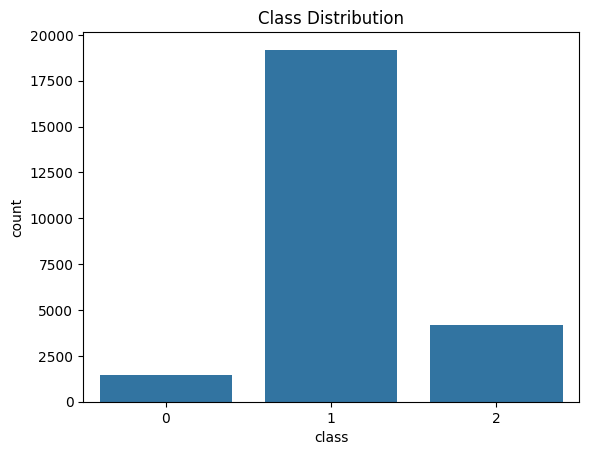

In [19]:
#class distribution
sns.countplot(x='class', data=df_1)
plt.title("Class Distribution")
plt.show()

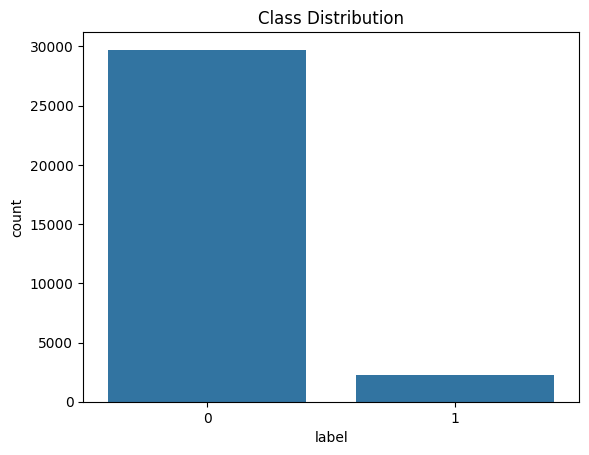

In [20]:
#class distribution
sns.countplot(x='label', data=df_2)
plt.title("Class Distribution")
plt.show()

In [24]:
#hate bigram analysis (2,2)
from sklearn.feature_extraction.text import CountVectorizer
hate_texts = df_1[df_1['class'] == 1]['tweet']
non_hate_texts = df_1[df_1['class'] == 0]['tweet']
vectorizer_1 = CountVectorizer(
    ngram_range=(2,2),
    stop_words='english',
    max_features=20
)

X_hate = vectorizer_1.fit_transform(hate_texts)

bigrams = vectorizer_1.get_feature_names_out()
counts = X_hate.sum(axis=0).A1

bigram_df = pd.DataFrame({
    'bigram': bigrams,
    'count': counts
}).sort_values(by='count', ascending=False)

print("Top Hate Speech Bigrams:")
print(bigram_df)

Top Hate Speech Bigrams:
           bigram  count
2   128514 128514   1582
10      bitch ass    227
4   128557 128557    218
16     like bitch    216
19       yo bitch    190
6       ass bitch    186
8       bad bitch    183
18      look like    151
9     bad bitches    147
12     bitch http    136
3   128514 128557    132
13     fuck bitch    129
11      bitch don    127
1   128175 128175    121
17   little bitch    121
0     12288 12288    119
14          gt gt    116
7       ass nigga    110
15       hoes ain    110
5     8221 128514    104


In [25]:
#hate bigram analysis (2,2)
from sklearn.feature_extraction.text import CountVectorizer
hate_texts = df_2[df_2['label'] == 1]['tweet']
non_hate_texts = df_2[df_2['label'] == 0]['tweet']
vectorizer_2 = CountVectorizer(
    ngram_range=(2,2),
    stop_words='english',
    max_features=20
)

X_hate = vectorizer_2.fit_transform(hate_texts)

bigrams = vectorizer_2.get_feature_names_out()
counts = X_hate.sum(axis=0).A1

bigram_df = pd.DataFrame({
    'bigram': bigrams,
    'count': counts
}).sort_values(by='count', ascending=False)

print("Top Hate Speech Bigrams:")
print(bigram_df)

Top Hate Speech Bigrams:
                bigram  count
18           user user    473
16      user allahsoil     83
6      libtard libtard     72
5     liberal politics     72
7          libtard sjw     72
12         sjw liberal     72
9       listen retweet     51
4            feel like     50
0             amp feel     49
8        like stomping     46
13     stomping listen     43
17        user libtard     41
1            black amp     32
10       retweet tampa     32
15         thanks user     28
14        tampa miamiâ     28
3         condemns act     26
2          calgary wso     26
11         sikh temple     26
19  vandalised calgary     26


In [26]:
#non hate bigram analysis (2,2)
vectorizer_1 = CountVectorizer(
    ngram_range=(2,2),
    stop_words='english',
    max_features=20
)

X_nonhate = vectorizer_1.fit_transform(non_hate_texts)

bigrams = vectorizer_1.get_feature_names_out()
counts = X_nonhate.sum(axis=0).A1

bigram_df_nonhate = pd.DataFrame({
    'bigram': bigrams,
    'count': counts
}).sort_values(by='count', ascending=False)

print("Top Non-Hate Bigrams:")
print(bigram_df_nonhate)

Top Non-Hate Bigrams:
                   bigram  count
19              user user   3805
16      thankful positive    429
7              father day    417
10          i_am positive    352
14   positive affirmation    352
12             model love    326
11              love time    325
17               time urð    325
2             blog silver    295
15            silver gold    283
9              gold forex    263
0   altwaystoheal healthy    239
8             fathers day    219
13             polar bear    215
5             direct want    175
3             bull direct    175
6           dominate bull    175
4           bull dominate    175
18              user just    169
1               bing bong    150


In [27]:
#non hate bigram analysis (2,2)
vectorizer_2 = CountVectorizer(
    ngram_range=(2,2),
    stop_words='english',
    max_features=20
)

X_nonhate = vectorizer_2.fit_transform(non_hate_texts)

bigrams = vectorizer_2.get_feature_names_out()
counts = X_nonhate.sum(axis=0).A1

bigram_df_nonhate = pd.DataFrame({
    'bigram': bigrams,
    'count': counts
}).sort_values(by='count', ascending=False)

print("Top Non-Hate Bigrams:")
print(bigram_df_nonhate)

Top Non-Hate Bigrams:
                   bigram  count
19              user user   3805
16      thankful positive    429
7              father day    417
10          i_am positive    352
14   positive affirmation    352
12             model love    326
11              love time    325
17               time urð    325
2             blog silver    295
15            silver gold    283
9              gold forex    263
0   altwaystoheal healthy    239
8             fathers day    219
13             polar bear    215
5             direct want    175
3             bull direct    175
6           dominate bull    175
4           bull dominate    175
18              user just    169
1               bing bong    150
